# SSS restoring maps and timeseries

See
- https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/44
- https://github.com/ACCESS-NRI/dev_coupling/issues/63#issuecomment-3383664728
- https://github.com/AndyHoggANU/ACCESS-CM2-025-diagnostics/blob/5786ccf/MarginalSeas.ipynb

In [1]:
# These first two cells must be in all notebooks!
# It allows us to run all the notebooks at once, this cell has a tag "parameters" which allows us to pass in 
# arguments externally using papermill (see mkfigs.sh for details)

# Set esm_file to the datastore for the main experiment of interest
# esm_file = "/g/data/ol01/outputs/access-om3-25km/25km-iaf-test-for-AK-expt-7df5ef4c/datastore.json"
# esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-5165c0f8/datastore.json"
# esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-00532b88/datastore.json"
esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test4-d28e0359/datastore.json"

# papermill settings. *No need to modify these if running interactively.* 
papermill = False                      # `cwd` and `nbname` will be populated by papermill.
cwd = None                             # current working directory 
nbname = None                          # notebook name

In [2]:
# Parameters
esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/datastore.json"
papermill = True
cwd = "/g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/"
nbname = "SSS_Restoring_Timeseries.ipynb"


In [3]:
import os
if not papermill: 
    import nci_ipynb  # requires conda/analysis3-26.03 or later
    cwd = nci_ipynb.dir()
    nbname = nci_ipynb.name()
    os.chdir(cwd)
import mkfigs_bootstrap  # noqa: adds external/access-model-mkfigs/src to sys.path (stop-gap)
from mkfigs import MkmdWriter
mkmd = MkmdWriter(esm_file, nbname, str(cwd), pm=papermill)

In [4]:
import xarray as xr
import gsw
import intake
from dask.distributed import Client
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import cmocean as cm
import cartopy.crs as ccrs
from shapely import geometry
import calendar
import cftime
import textwrap
import numpy as np
from tqdm.notebook import tqdm

In [5]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [6]:
client = Client(threads_per_worker=1)
print(client.dashboard_link)

http://127.0.0.1:8787/status


In [7]:
def _patch_worker_coverage():
    """Workaround: numba expects coverage.types attrs missing in this conda env's coverage version."""
    try:
        import sys, types, coverage
        class _TypesProxy(types.ModuleType):
            def __getattr__(self, name):
                val = type(name, (), {})
                setattr(self, name, val)
                return val
        proxy = _TypesProxy('coverage.types')
        proxy.__dict__.update(vars(coverage.types))
        coverage.types = proxy
        sys.modules['coverage.types'] = proxy
    except Exception:
        pass

_patch_worker_coverage()
client.run(_patch_worker_coverage)

{'tcp://127.0.0.1:33975': None,
 'tcp://127.0.0.1:34053': None,
 'tcp://127.0.0.1:34101': None,
 'tcp://127.0.0.1:34315': None,
 'tcp://127.0.0.1:38653': None,
 'tcp://127.0.0.1:38699': None,
 'tcp://127.0.0.1:38705': None,
 'tcp://127.0.0.1:39865': None,
 'tcp://127.0.0.1:39867': None,
 'tcp://127.0.0.1:40049': None,
 'tcp://127.0.0.1:40727': None,
 'tcp://127.0.0.1:41133': None,
 'tcp://127.0.0.1:41675': None,
 'tcp://127.0.0.1:41993': None,
 'tcp://127.0.0.1:44201': None,
 'tcp://127.0.0.1:46715': None}

In [8]:
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 16
Total threads: 16,Total memory: 188.56 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:45905,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:33975,Total threads: 1
Dashboard: http://127.0.0.1:46059/status,Memory: 11.78 GiB
Nanny: tcp://127.0.0.1:39825,


In [9]:
IAF = esm_file.find('iaf') > 0
IAF

# Averaging window for the maps: last NYEARS complete years, or an explicit [first, last] period
averaging_period = None   # e.g. [1908, 1909]; None = automatic
NYEARS = 2
from model_agnostic import complete_years, years_window, year_slice

In [10]:
om3exptname = os.path.basename(os.path.dirname(esm_file))
om3exptname

'MC_25km_jra_iaf+wombatlite-test5.1-8f50b769'

## Load ACCESS-OM3 data from ESM datastore

In [11]:
catalogs = [
                # '/g/data/ol01/access-om3-output/access-om3-025/25km-iaf-test-for-AK-expt-7df5ef4c/datastore.json',
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-5165c0f8/datastore.json',
                '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-00532b88/datastore.json',
                '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-COARE-12fab415/datastore.json',
                esm_file,
                "/g/data/ol01/outputs/access-om3-100km/MC_100km_jra_ryf+wombatlite-1e74abf-11f9df5c/experiment_datastore.json",
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-gm1-d968c801/datastore.json',
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-gm2-5dc49da6/datastore.json',
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-gm3-da330542/datastore.json',
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-gm4-9fd08880/datastore.json',
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-gm5-9b5dbfa9/datastore.json',
            ]
if not IAF:
    catalogs = [esm_file]  # the IAF comparison runs above don't share model years with an RYF run
catalogs

['/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-00532b88/datastore.json',
 '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-COARE-12fab415/datastore.json',
 '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/datastore.json',
 '/g/data/ol01/outputs/access-om3-100km/MC_100km_jra_ryf+wombatlite-1e74abf-11f9df5c/experiment_datastore.json']

In [12]:
om3datastores = { os.path.normpath(c).split(os.sep)[-2]:
               intake.open_esm_datastore(c,
                                         columns_with_iterables=[
                                            "variable",
                                            "variable_long_name",
                                            "variable_standard_name",
                                            "variable_cell_methods",
                                            "variable_units"]
                                        )
              for c in catalogs }
om3datastores

{'MC_25km_jra_iaf+wombatlite-test3v2-00532b88': <datastore catalog with 24 dataset(s) from 32927 asset(s)>,
 'MC_25km_jra_iaf+wombatlite-test3v2-COARE-12fab415': <datastore catalog with 24 dataset(s) from 16791 asset(s)>,
 'MC_25km_jra_iaf+wombatlite-test5.1-8f50b769': <datastore catalog with 24 dataset(s) from 11154 asset(s)>,
 'MC_100km_jra_ryf+wombatlite-1e74abf-11f9df5c': <experiment_datastore catalog with 15 dataset(s) from 8540 asset(s)>}

In [13]:
om3varnames = [
                "salt_flux_added",
                "sos",
              ]

om3vars = {
    vname: {expt: ds.search(variable=vname).to_dask(
                xarray_open_kwargs = dict(
                    # chunks={"xh": -1, "yh": -1},
                    chunks={"time": -1},
                    decode_timedelta=True,
                    use_cftime=True
                )
            )[vname]
            for expt, ds in om3datastores.items()
          }
    for vname in om3varnames
    }

for vname in om3varnames:
    # define cell-area-weighted versions of all variables
    vname_int = f"{vname}_int"
    om3vars[vname_int] = dict()
    for expt, ds in om3datastores.items():
        cell_area = ds.search(variable='areacello',
                              path=".*output000.*").to_dask(
                                xarray_open_kwargs = dict(
                                    # chunks={"xh": -1, "yh": -1}
                                    chunks={"time": -1}
                                )
                              )['areacello']
        om3vars[vname_int][expt] = om3vars[vname][expt] * cell_area

for expt, d in om3vars["sos"].items():
  # resample monthly to match salt_flux_added and OM2 data
    om3vars["sos"][expt] = d.resample(time='ME').mean('time')
    
# omit latitudes with grid bug in this run https://github.com/ACCESS-NRI/ocean_model_grid_generator/issues/7
for vname, d in om3vars.items():
    try:
        d['25km-iaf-test-for-AK-expt-7df5ef4c'] = d['25km-iaf-test-for-AK-expt-7df5ef4c'].isel(yh=slice(10, None))
    except ValueError:
        d['25km-iaf-test-for-AK-expt-7df5ef4c'] = d['25km-iaf-test-for-AK-expt-7df5ef4c'].isel(yq=slice(10, None))
    except KeyError:
        pass

if IAF:
    for vname, d in om3vars.items():
        for expt in d:
            try:
                d[expt] = d[expt].convert_calendar("proleptic_gregorian", use_cftime=True)
            except KeyError:
                pass

# RYF spin-up runs use a synthetic calendar (e.g. starting ~1900s) unrelated
# to real forcing dates, so their time axis doesn't overlap the IAF
# experiments' real dates at all -- relabel it onto the primary experiment's
# real time axis so it plots on the same timescale as the others (same
# technique used for the RYF experiment in StraitTransports.ipynb).
_ryf_expt = 'MC_100km_jra_ryf+wombatlite-1e74abf-11f9df5c'
if _ryf_expt in om3datastores:
    _ref_time = om3vars['sos'][om3exptname].time
    for vname, d in om3vars.items():
        if _ryf_expt not in d:
            continue
        _da = d[_ryf_expt]  # avoid clobbering `ds`, which a later cell relies on
        n = min(_da.sizes['time'], _ref_time.sizes['time'])
        d[_ryf_expt] = (_da.isel(time=slice(None, n))
                          .assign_coords(time=('time', _ref_time.isel(time=slice(None, n)).values)))

In [14]:
om3vars

{'salt_flux_added': {'MC_25km_jra_iaf+wombatlite-test3v2-00532b88': <xarray.DataArray 'salt_flux_added' (time: 792, yh: 1152, xh: 1440)> Size: 5GB
  dask.array<getitem, shape=(792, 1152, 1440), dtype=float32, chunksize=(12, 192, 160), chunktype=numpy.ndarray>
  Coordinates:
    * time     (time) object 6kB 1958-01-16 12:00:00 ... 2023-12-16 12:00:00
    * yh       (yh) float64 9kB -81.58 -81.52 -81.45 -81.39 ... 89.74 89.84 89.95
    * xh       (xh) float64 12kB -279.9 -279.6 -279.4 -279.1 ... 79.38 79.62 79.88
  Attributes:
      units:          kg m-2 s-1
      long_name:      Salt flux into ocean at surface due to restoring or flux ...
      cell_methods:   area:mean yh:mean xh:mean time: mean
      cell_measures:  area: areacello
      time_avg_info:  average_T1,average_T2,average_DT,
  'MC_25km_jra_iaf+wombatlite-test3v2-COARE-12fab415': <xarray.DataArray 'salt_flux_added' (time: 408, yh: 1152, xh: 1440)> Size: 3GB
  dask.array<getitem, shape=(408, 1152, 1440), dtype=float32, chun

## Load ACCESS-OM2 data from ACCESS-NRI Catalog

use control - see https://forum.access-hive.org.au/t/access-om2-control-experiments/258#p-747-ryf-7 - but **note that this does not include topography fixes in the latest OM2 and CM2 configs** - see https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/44#issuecomment-3379637468

In [15]:
if IAF:
    om2exptname = '025deg_jra55_iaf_omip2_cycle1'
    frequency = '1mon'
else:
    om2exptname = '025deg_jra55_ryf9091_gadi'
    frequency='1mon' # 025deg_jra55_ryf9091_gadi has no 1yr sfc_salt_flux_restore

# datastore = intake.cat.access_nri[om2exptname]
om2datastores = {om2exptname: intake.cat.access_nri[om2exptname]}

In [16]:
om2varnames = [
                'sfc_salt_flux_restore',
                'surface_salt',  # uses surface values of 'salt' if 'surface_salt' unavailable
              ]

om2varnames = { k: k for k in om2varnames } # name_in_om2vars: varname_in_netcdf

if 'surface_salt' in om2varnames:
    try:
        _ = om2datastores[om2exptname].search(variable='surface_salt', frequency=frequency).to_dask()
    except ValueError:
        om2varnames['surface_salt'] = 'salt'  # fallback to 3d salt if surface salt unavailable

om2vars = {
    vname: {expt: ds.search(variable=vnamein, frequency=frequency).to_dask(
                xarray_open_kwargs = dict(
                    # chunks={"xt_ocean": -1, "yt_ocean": -1},
                    chunks={"time": -1},
                    decode_timedelta=True,
                    use_cftime=True
                )
            )[vnamein]
            for expt, ds in om2datastores.items()
          }
    for vname, vnamein in om2varnames.items()
    }

# take surface value of any 3d fields
for vname, d in om2vars.items():
    for expt in d:
        try:
            d[expt] = d[expt].isel(st_ocean=0)
        except ValueError:
            pass

for vname in om2varnames:
    # define cell-area-weighted versions of all variables
    vname_int = f"{vname}_int"
    om2vars[vname_int] = dict()
    for expt, ds in om2datastores.items():
        cell_area = ds.search(variable='area_t',
                              path=".*output000.*").to_dask(
                                xarray_open_kwargs = dict(
                                    chunks={"xh": -1, "yh": -1})
                              )['area_t']
        om2vars[vname_int][expt] = om2vars[vname][expt] * cell_area

if IAF:
    for vname, d in om2vars.items():
        for expt in d:
            try:
                d[expt] = d[expt].convert_calendar("proleptic_gregorian", use_cftime=True)
            except KeyError:
                pass

In [17]:
om2vars

{'sfc_salt_flux_restore': {'025deg_jra55_iaf_omip2_cycle1': <xarray.DataArray 'sfc_salt_flux_restore' (time: 732, yt_ocean: 1080,
                                             xt_ocean: 1440)> Size: 5GB
  dask.array<getitem, shape=(732, 1080, 1440), dtype=float32, chunksize=(12, 216, 240), chunktype=numpy.ndarray>
  Coordinates:
    * time      (time) object 6kB 1958-01-14 12:00:00 ... 2018-12-14 12:00:00
    * yt_ocean  (yt_ocean) float64 9kB -81.08 -80.97 -80.87 ... 89.74 89.84 89.95
    * xt_ocean  (xt_ocean) float64 12kB -279.9 -279.6 -279.4 ... 79.38 79.62 79.88
  Attributes:
      long_name:      sfc_salt_flux_restore: flux from restoring term
      units:          kg/(m^2*sec)
      valid_range:    [-10000.  10000.]
      cell_methods:   time: mean
      time_avg_info:  average_T1,average_T2,average_DT},
 'surface_salt': {'025deg_jra55_iaf_omip2_cycle1': <xarray.DataArray 'salt' (time: 732, yt_ocean: 1080, xt_ocean: 1440)> Size: 5GB
  dask.array<getitem, shape=(732, 1080, 1440), 

### Trim to a consistent time range

In [18]:
# Time windows for the maps and SSS bias (the timeseries show the whole record).
om3time = om3vars['sos'][om3exptname].time
om2time = om2vars['surface_salt'][om2exptname].time
if averaging_period is not None:
    om3_window = years_window(om3time, period=averaging_period)
elif IAF:
    # IAF: real years, so use the last NYEARS complete years that every plotted run has
    # (the other OM3 runs in `catalogs` and the OM2 IAF reference)
    spans = [complete_years(om2time, frequency="monthly")]
    spans += [complete_years(om3vars['sos'][e].time) for e in om3datastores]
    om3_window = years_window(om3time, NYEARS, within=(max(s[0] for s in spans), min(s[-1] for s in spans)))
else:
    # RYF: model calendar years are arbitrary; use the last NYEARS complete years of the run
    om3_window = years_window(om3time, NYEARS)
# OM2 reference: same years where it has them (warns and falls back to its first NYEARS years otherwise)
om2_window = years_window(om2time, NYEARS, within=om3_window, frequency="monthly")  # monthly: see om2 search above

timeslice = year_slice(om3_window)
om2timeslice = year_slice(om2_window)
period = f"{om3_window[0]}-{om3_window[1]} mean"
om2period = f"{om2_window[0]}-{om2_window[1]} mean"
print('ACCESS-OM3 window:', om3_window, '| ACCESS-OM2 window:', om2_window)

ACCESS-OM3 window: (2006, 2007) | ACCESS-OM2 window: (2006, 2007)


## Make plots

### Define regions
- match https://github.com/AndyHoggANU/ACCESS-CM2-025-diagnostics/blob/5786ccf/MarginalSeas.ipynb
- see https://github.com/ACCESS-NRI/dev_coupling/issues/63#issuecomment-3383664728

Text(0.5, 1.0, 'Regions (BUG: incorrect shapes north of 65°N)')

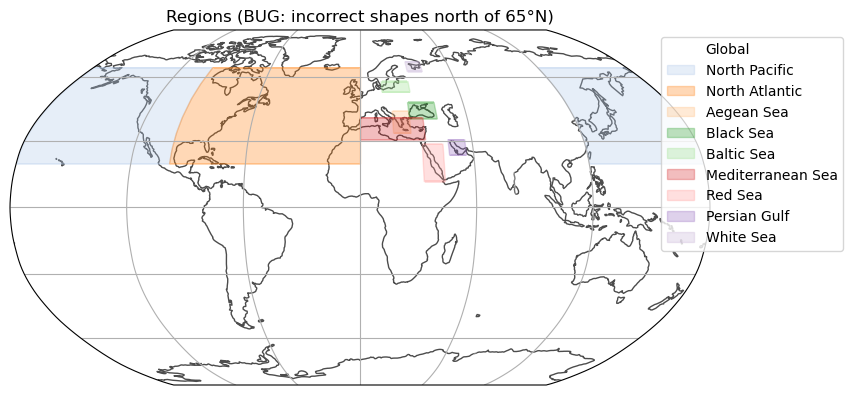

In [19]:
regions = { # [minx, maxx, miny, maxy], using model longitude range (-280 to 80)
    "Global": [-280, 80, -90, 90],
    # # "Arctic": [-280, 80, 65, 90],
    # # "Southern Ocean": [-280, 80, -82, -63],
    # # "ACC": [-280, 80, -63, -45],
    # # "Southern Pacific": [-210, -70, -45, -20],
    # # "Tropical Pacific": [-240, -100, -20, 20],
    "North Pacific": [-240, -100, 20, 65],
    # # "South Atlantic": [-60, 20, -45, -20],
    # # "Tropical Atlantic": [-70, 20, -20, 20],
    "North Atlantic": [-100, 0, 20, 65],
    #"Indian": [30, 120, -45, 20],
    "Aegean Sea": [18, 27.5, 34, 44],
    "Black Sea": [27.5, 43, 40.5, 48],
    "Baltic Sea": [13, 30, 53, 58],
    "Mediterranean Sea": [0, 35, 31, 41],
    "Red Sea": [33, 44, 12, 29],
    "Persian Gulf": [47, 56, 24, 31],
    "White Sea": [31, 41, 63, 68],
}
regions = {k: dict(zip(["minx", "maxx", "miny", "maxy"], v)) for k, v in regions.items()}  # convert to dicts

for r, d in regions.items():
    for k, x in d.items():
        if k in ["minx", "maxx"] and x != max(-280, min(x, 80)):
            raise ValueError(f"{r} {k} = {x} is outside the range -280 to 80")

fig = plt.figure(figsize=(10, 4))

colors = mpl.color_sequences['tab20']
try:  # set Global color to white 
    colors[list(regions.keys()).index("Global")] = (1, 1, 1)
except ValueError:
    pass

ax = plt.axes(position=[0.05,0.05,0.7,0.9], projection=ccrs.Robinson())
ax.coastlines(resolution="110m")
ax.gridlines(draw_labels=False)

legend_elements = []
for i, (region, limits) in enumerate(regions.items()):
    ax.add_geometries([geometry.box(**limits)], crs=ccrs.PlateCarree(), color=colors[i], alpha=0.3)
    legend_elements.append(Patch(color=colors[i], alpha=0.3, label=region))

ax.legend(handles=legend_elements, bbox_to_anchor=(1.2, 1.00))
plt.title("Regions (BUG: incorrect shapes north of 65°N)")

### Timeseries

Global


North Pacific


North Atlantic


Aegean Sea


Black Sea


Baltic Sea


Mediterranean Sea


Red Sea


Persian Gulf


White Sea


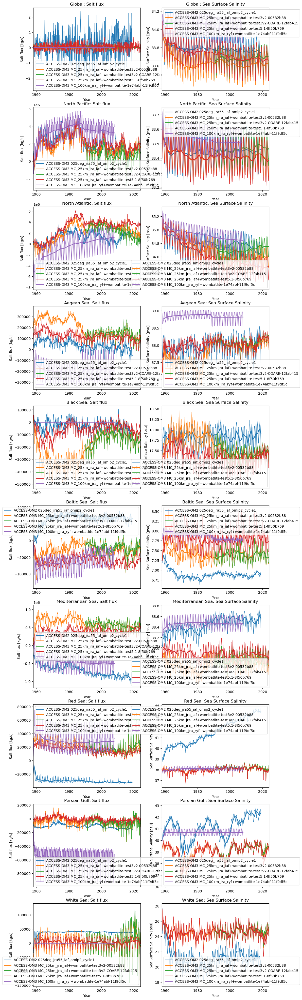

In [20]:
fig, axes = plt.subplots(nrows=len(regions), ncols=2, figsize=(12, 5*len(regions)))
for i, (region, bounds) in enumerate(regions.items()):
    print(region)
    minx, maxx, miny, maxy = bounds.values()

    try:
        ax1 = axes[i, 0]  # left column: restoring
    except IndexError:
        ax1 = axes[0]
    for expt, data in om2vars['sfc_salt_flux_restore_int'].items():
        d = ( data
            .sel(xt_ocean=slice(minx, maxx), yt_ocean=slice(miny, maxy))
            .sum(['xt_ocean', 'yt_ocean'], keep_attrs=True)
            .load()
            )
        p = d.plot(ax=ax1, linewidth=.7)
        d.resample(time='1YE').mean('time').plot(
                    ax=ax1,
                    linewidth=2,
                    color=p[-1].get_color(),
                    label=f"ACCESS-OM2 {expt}"
                )
    for expt, data in om3vars['salt_flux_added_int'].items():
        d = ( data
            .sel(xh=slice(minx, maxx), yh=slice(miny, maxy))
            .sum(['xh', 'yh'], keep_attrs=True)
            .load()
            )
        p = d.plot(ax=ax1, linewidth=.7)
        d.resample(time='1YE').mean('time').plot(
                    ax=ax1,
                    linewidth=2,
                    color=p[-1].get_color(),
                    label=f"ACCESS-OM3 {expt}"
                )
    ax1.set_ylabel("Salt flux [kg/s]")
    ax1.set_title(f"{region}: Salt flux")
    ax1.set_xlabel("Year")
    ax1.autoscale(enable=True, axis='x', tight=True)
    if IAF:
        ax1.set_xlim(right=cftime.DatetimeProlepticGregorian(2023, 12, 31))
    else:
        ax1.set_xlim(om3time.values[0], om3time.values[-1])  # RYF: the OM3 run (OM2 RYF control is much longer)
    ax1.legend()

    try:
        ax1 = axes[i, 1]  # right column: SST
    except IndexError:
        ax1 = axes[1]
    for expt, data in om2vars['surface_salt'].items():
        d = ( data
            # .sel(xt_ocean=slice(minx, maxx)).mean('xt_ocean', keep_attrs=True)
            # .sel(yt_ocean=slice(miny, maxy)).mean('yt_ocean', keep_attrs=True)
            .sel(xt_ocean=slice(minx, maxx), yt_ocean=slice(miny, maxy))
            .mean(['xt_ocean', 'yt_ocean'], keep_attrs=True)  # BUG: not area-weighted
            .load()
            )
        p = d.plot(ax=ax1, linewidth=.7)
        d.resample(time='1YE').mean('time').plot(
                    ax=ax1,
                    linewidth=2,
                    color=p[-1].get_color(),
                    label=f"ACCESS-OM2 {expt}"
                )
    for expt, data in om3vars['sos'].items():
        d = ( data
            # .sel(xh=slice(minx, maxx)).mean('xh', keep_attrs=True)
            # .sel(yh=slice(miny, maxy)).mean('yh', keep_attrs=True)
            .sel(xh=slice(minx, maxx), yh=slice(miny, maxy))
            .mean(['xh', 'yh'], keep_attrs=True)  # BUG: not area-weighted
            .load()
            )
        p = d.plot(ax=ax1, linewidth=.7)
        d.resample(time='1YE').mean('time').plot(
                    ax=ax1,
                    linewidth=2,
                    color=p[-1].get_color(),
                    label=f"ACCESS-OM3 {expt}"
                )
    ax1.set_ylabel(f"{d.attrs['long_name']} [{d.attrs['units']}]")
    ax1.set_title(f"{region}: {d.attrs['long_name']}")
    ax1.set_xlabel("Year")
    ax1.autoscale(enable=True, axis='x', tight=True)
    if IAF:
        ax1.set_xlim(right=cftime.DatetimeProlepticGregorian(2023, 12, 31))
    else:
        ax1.set_xlim(om3time.values[0], om3time.values[-1])  # RYF: the OM3 run (OM2 RYF control is much longer)
    ax1.legend()


### Maps

Global


North Pacific


North Atlantic


Aegean Sea


Black Sea


Baltic Sea


Mediterranean Sea


Red Sea


Persian Gulf


White Sea


CPU times: user 23.4 s, sys: 8.91 s, total: 32.4 s
Wall time: 31.5 s


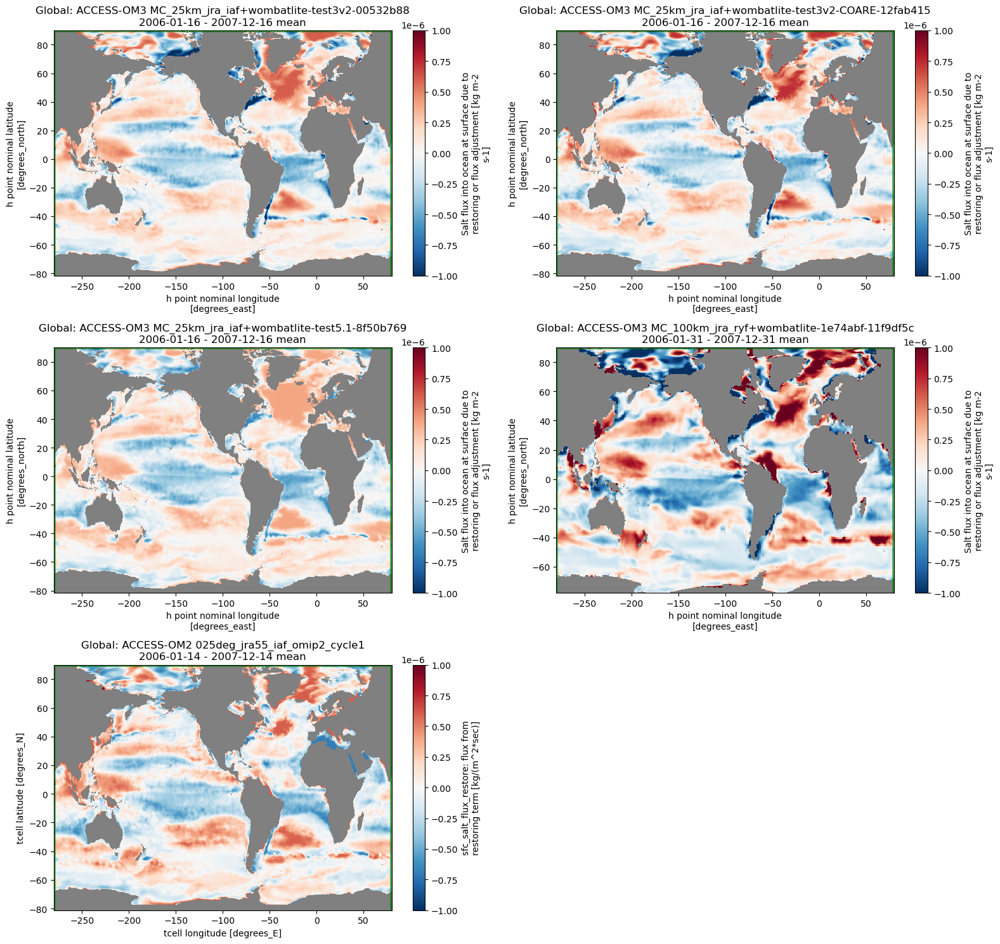

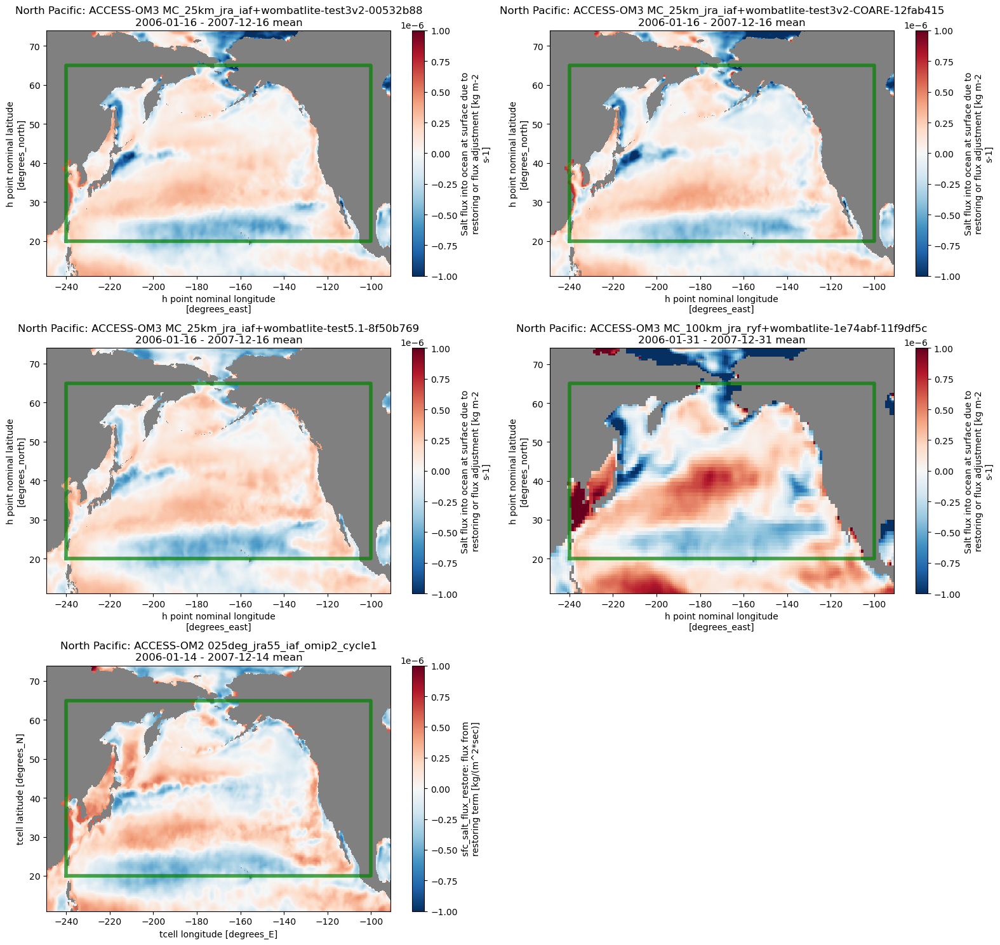

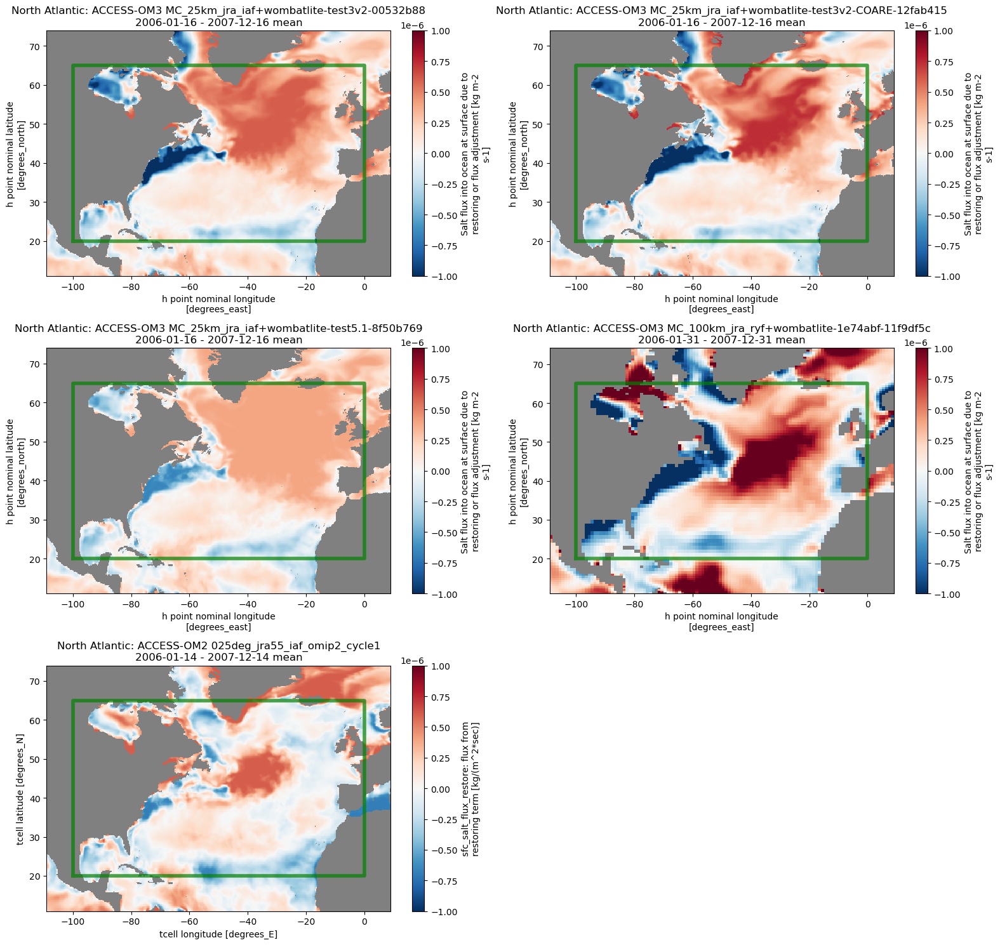

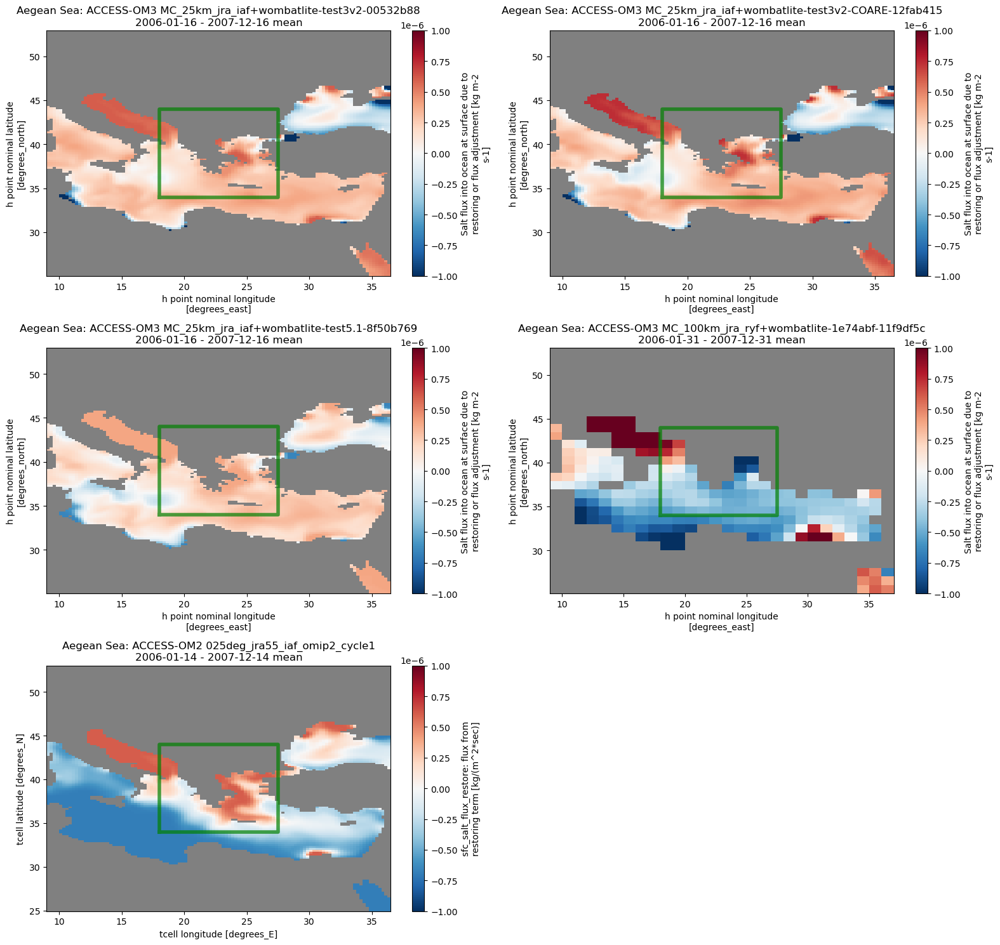

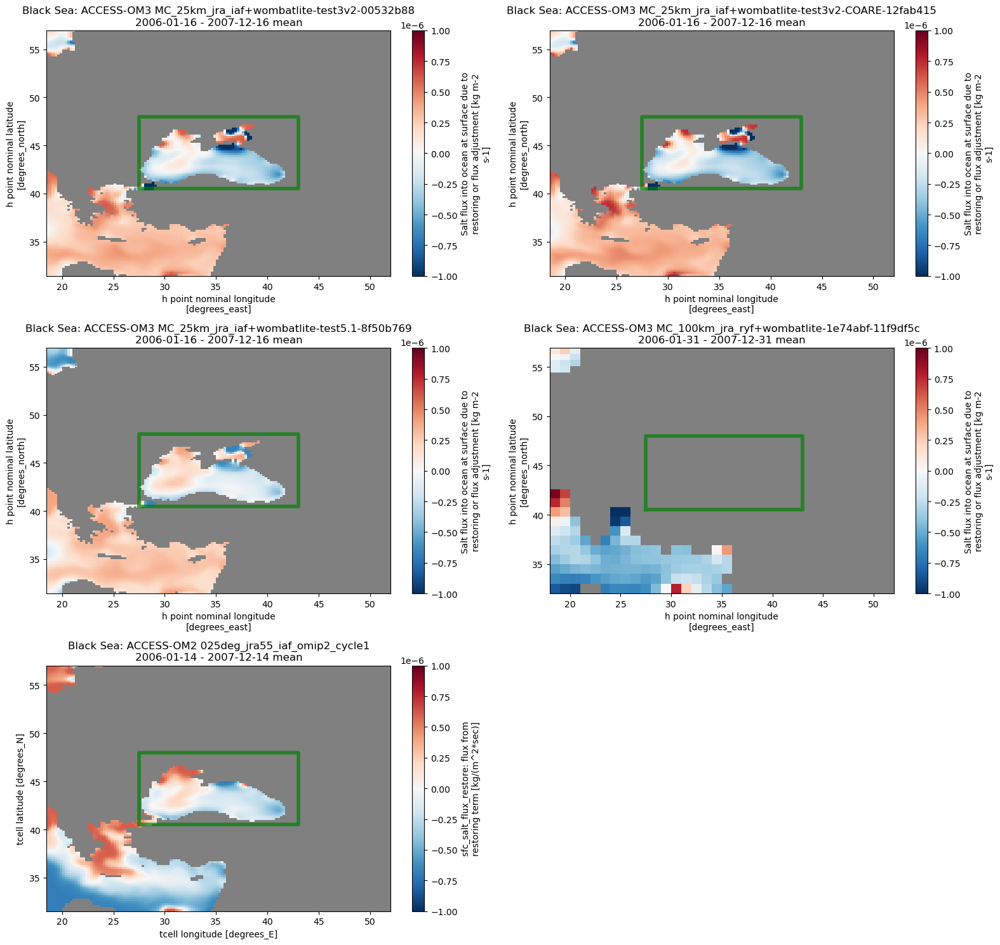

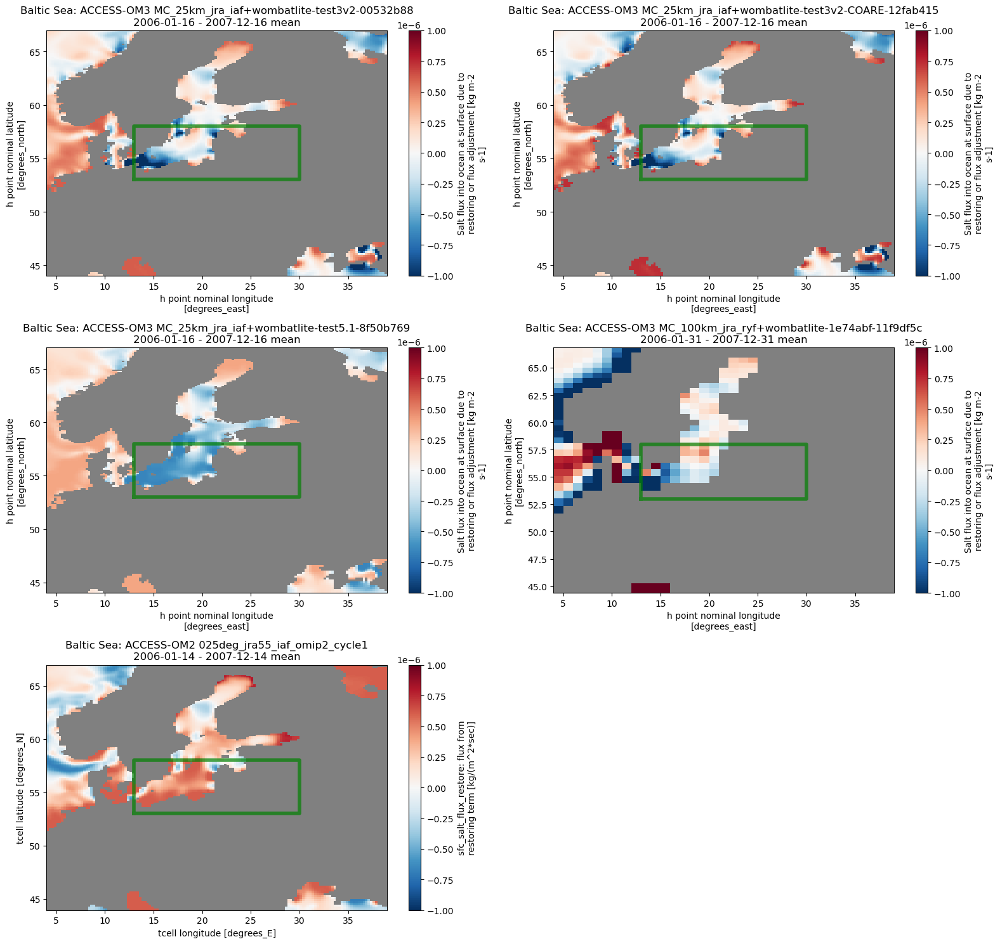

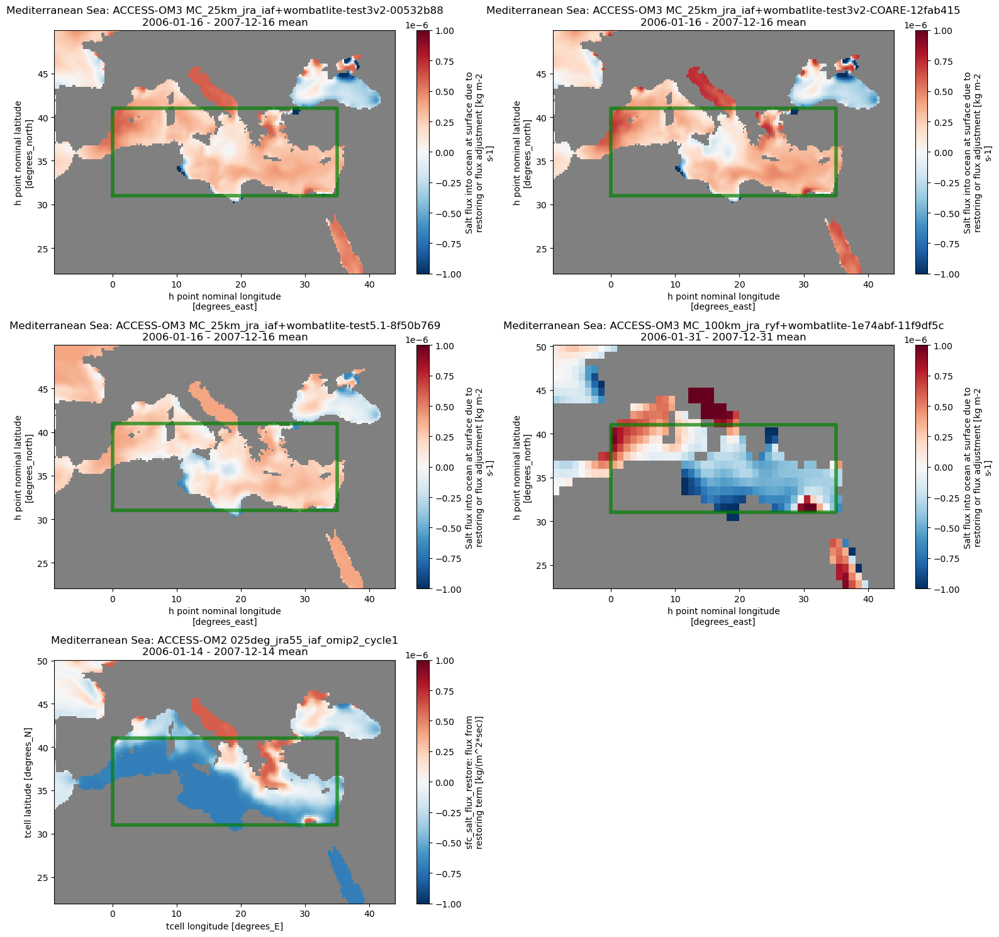

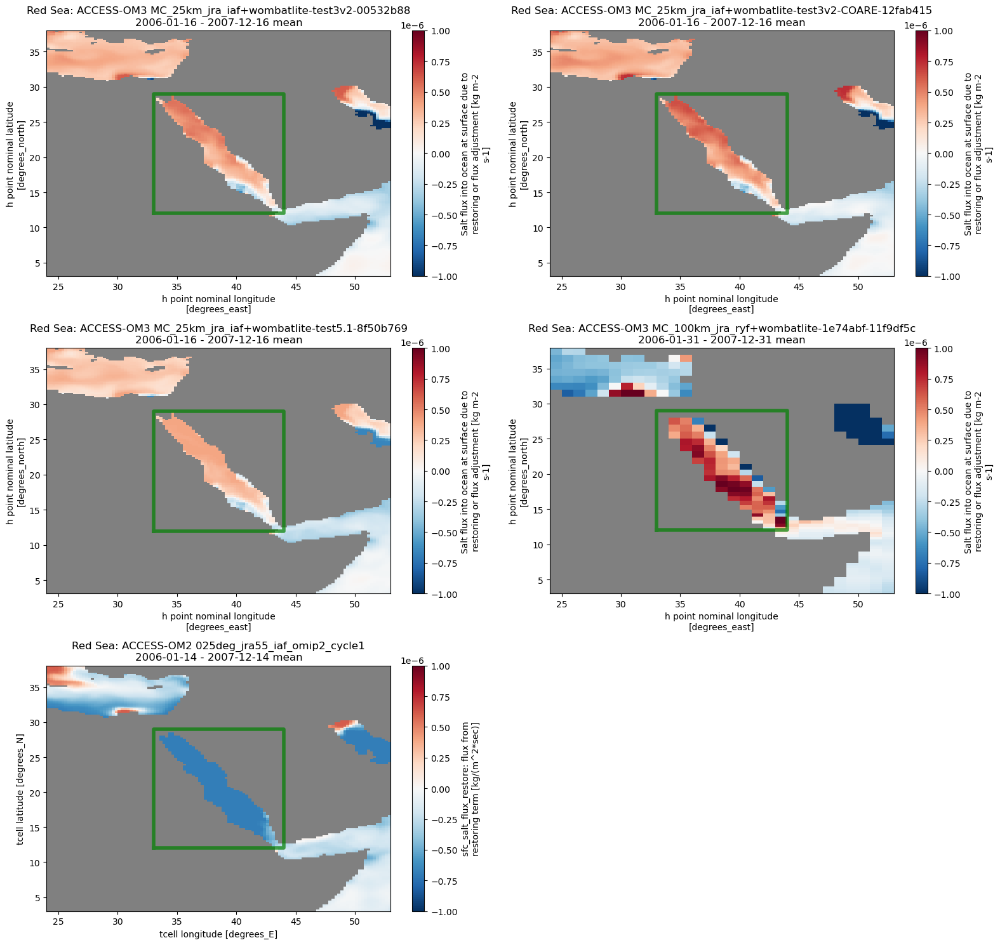

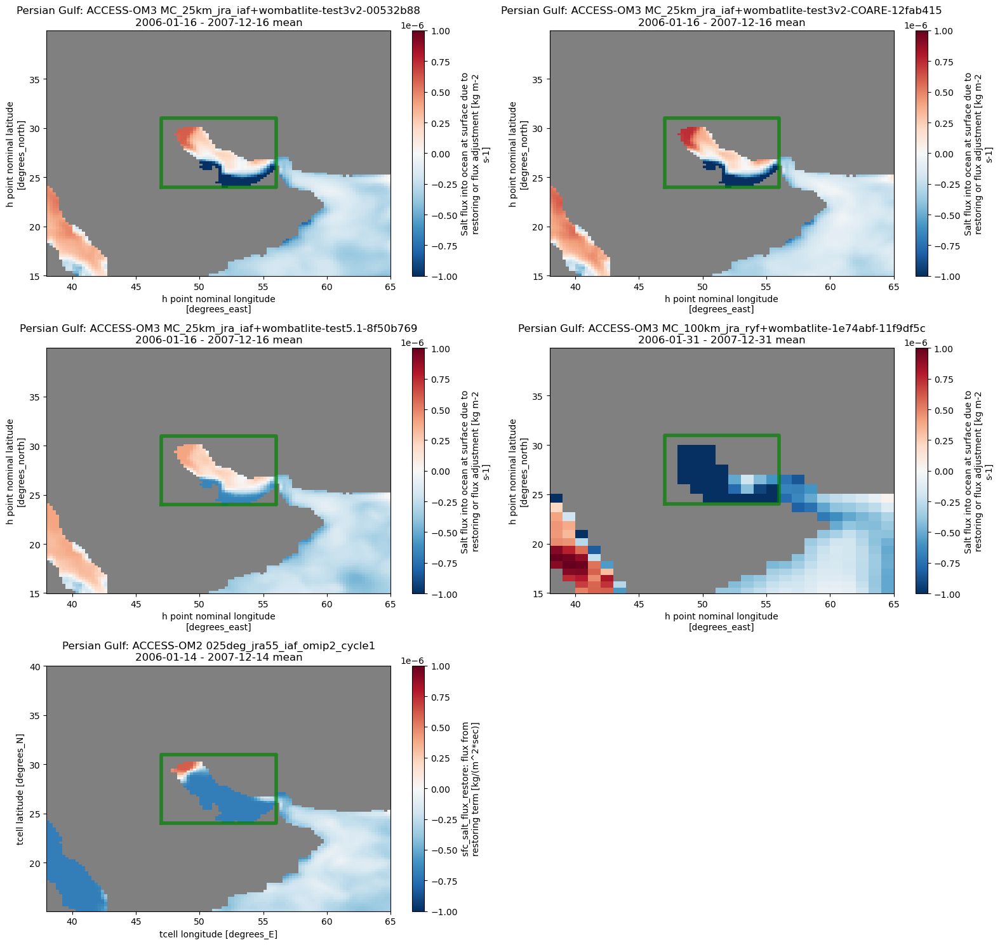

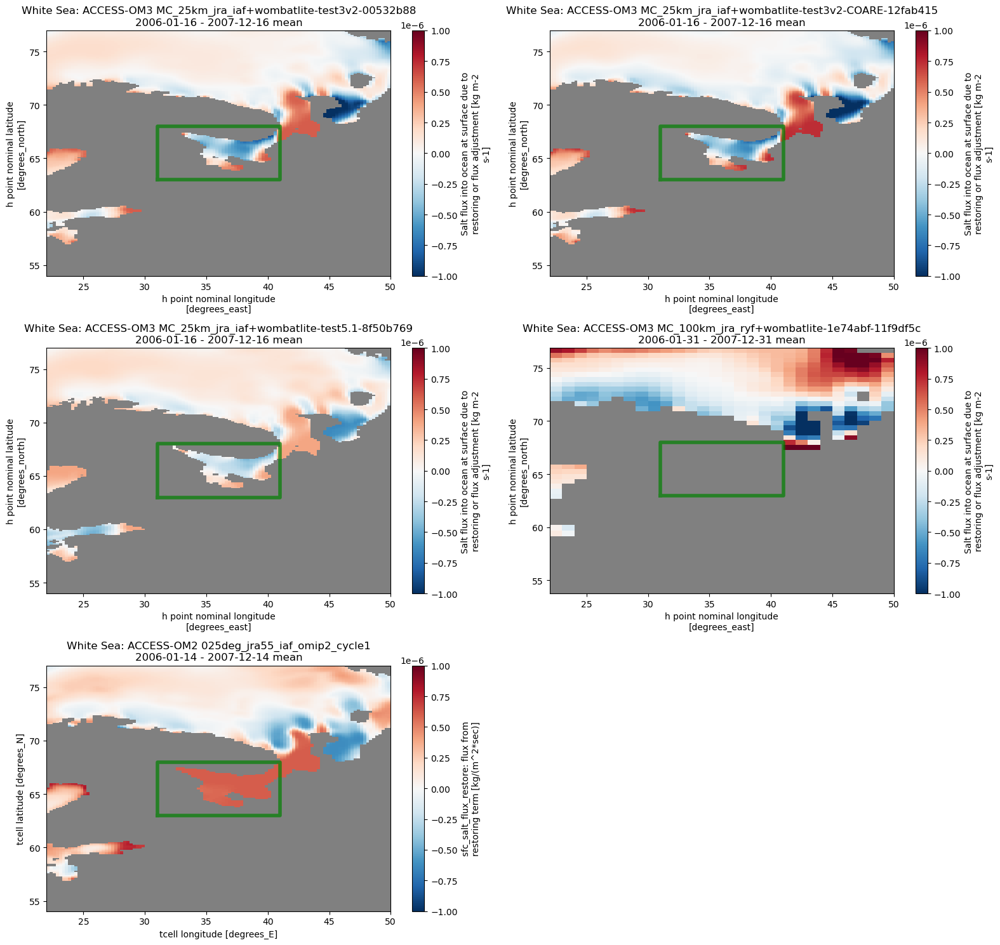

In [21]:
%%time
margin = 9
vmax = 1e-6
om3variable = "salt_flux_added"
om2variable = "sfc_salt_flux_restore"
for region, bounds in regions.items():
    print(region)
    minx, maxx, miny, maxy = bounds.values()
    xslice = slice(minx-margin, maxx+margin)
    yslice = slice(miny-margin, maxy+margin)
    npanels = len(om3vars[om3variable]) + len(om2vars[om2variable])
    nrows = (npanels+1)//2
    fig, axs = plt.subplots(nrows, 2,
                            figsize=(16, 5*nrows))
                            # figsize=(9, 3*nrows))

    # ACCESS-OM3
    for i, (expt, d) in enumerate(om3vars[om3variable].items(), start=1):
        plt.subplot(nrows, 2, i).set_facecolor('gray')  # gray land points
        data = d.sel(xh=xslice, yh=yslice, time=timeslice)
        p1 = data.mean('time').plot(vmax=vmax, add_colorbar=False)
        plt.plot([minx, maxx, maxx, minx, minx],
                 [miny, miny, maxy, maxy, miny],
                 color='green', linewidth=4, alpha=0.7)
        plt.title(f'{region}: ACCESS-OM3 {expt}\n{data.time.values[0].strftime("%Y-%m-%d")} - {data.time.values[-1].strftime("%Y-%m-%d")} mean')
        cbar1 = plt.colorbar(p1, orientation="vertical")
        cbar1.set_label('\n'.join(textwrap.wrap(
            f"{d.attrs['long_name']} [{d.attrs['units']}]",
            width=40)))

    # ACCESS-OM2
    for i, (expt, d) in enumerate(om2vars[om2variable].items(), start=i+1):
        plt.subplot(nrows, 2, i).set_facecolor('gray')  # gray land points
        data = d.sel(xt_ocean=xslice, yt_ocean=yslice, time=om2timeslice)
        p1 = data.mean('time').plot(vmax=vmax, add_colorbar=False)
        plt.plot([minx, maxx, maxx, minx, minx],
                 [miny, miny, maxy, maxy, miny],
                 color='green', linewidth=4, alpha=0.7)
        plt.title(f'{region}: ACCESS-OM2 {expt}\n{data.time.values[0].strftime("%Y-%m-%d")} - {data.time.values[-1].strftime("%Y-%m-%d")} mean')
        cbar1 = plt.colorbar(p1, orientation="vertical")
        cbar1.set_label('\n'.join(textwrap.wrap(
            f"{d.attrs['long_name']} [{d.attrs['units']}]",
            width=40)))

    try:  # drop empty subfigs (if any)
        fig.delaxes(axs.flatten()[i])
    except IndexError:
        pass

    plt.tight_layout()

## Compare salt restoring (expressed as equivalent freshwater flux) to E-P and sea ice fluxes

- salt_flux_added:long_name = "Salt flux into ocean at surface due to restoring or flux adjustment" ;
- salt_flux_added:units = "kg m-2 s-1" ;        <--- **salt** mass flux, not water mass mass
  
- wfo:long_name = "Water Flux Into Sea Water" ;
- wfo:units = "kg m-2 s-1" ;

- evs:long_name = "Water Evaporation Flux Where Ice Free Ocean over Sea" ;
- evs:units = "kg m-2 s-1" ;

- precip:long_name = "Liquid + frozen precipitation into ocean" ;
- precip:units = "kg m-2 s-1" ;

- ficeberg:long_name = "Water Flux into Seawater from Icebergs" ;
- ficeberg:units = "kg m-2 s-1" ;


#### Note the units.
- 1 kg m-2 s-1 = 1 mm/s = 86400 mm/day for water
- Convert from salt mass flux to equivalent fresh water mass flux by dividing by salinity (in units of kg salt/kg seawater water, ie PSU/1000) and changing sign

In [22]:
# add some more variables to om3vars, but only for expt
expt = om3exptname
varnames = [
                "salt_flux_added",
                "sos",
                "wfo",
                "evs",
                "precip",
                "ficeberg",
            ]

for vname in varnames:
    if vname not in om3vars or len(om3vars[vname]) == 0:
        print('adding ', vname)
        om3vars[vname] = dict()
        om3vars[vname][expt] = om3datastores[expt].search(variable=vname).to_dask(
                xarray_open_kwargs = dict(
                    # chunks={"xh": -1, "yh": -1},
                    chunks={"time": -1},
                    decode_timedelta=True,
                    use_cftime=True
                )
            )[vname]
        if IAF:
            om3vars[vname][expt] = om3vars[vname][expt].convert_calendar("proleptic_gregorian", use_cftime=True)

adding  wfo


adding  evs


adding  precip


adding  ficeberg


In [23]:
# add salt_flux_added_as_water to om3vars, but only for expt

factor = om3vars['sos'][expt]/1000  # converts sos from ppt
factor['time'] = om3vars['salt_flux_added'][expt].time  # deal with offset time
salt_flux_added_as_water = -om3vars['salt_flux_added'][expt] / factor  # express salt flux as equivalent freshwater flux
salt_flux_added_as_water.attrs = om3vars['salt_flux_added'][expt].attrs
salt_flux_added_as_water.attrs['long_name'] = salt_flux_added_as_water.attrs['long_name'] + ", expressed as equivalent water flux"

om3vars['salt_flux_added_as_water'] = dict()
om3vars['salt_flux_added_as_water'][expt] = salt_flux_added_as_water

salt_flux_added_as_water


wfo


evs


precip


ficeberg


CPU times: user 12.2 s, sys: 4.1 s, total: 16.3 s
Wall time: 32.2 s


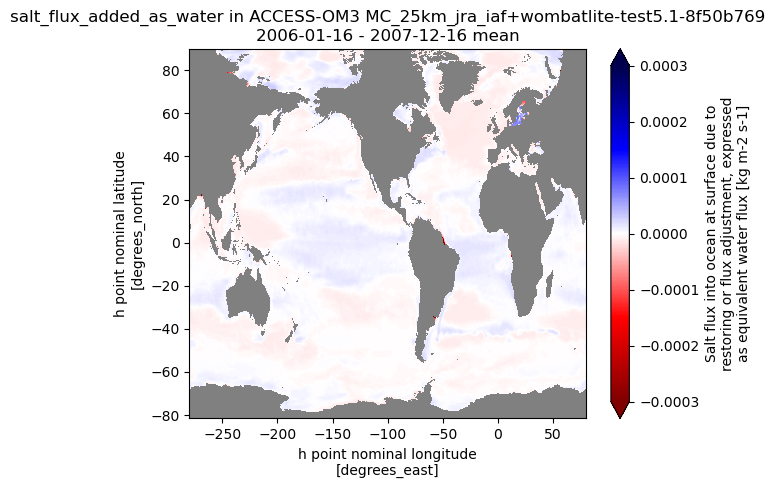

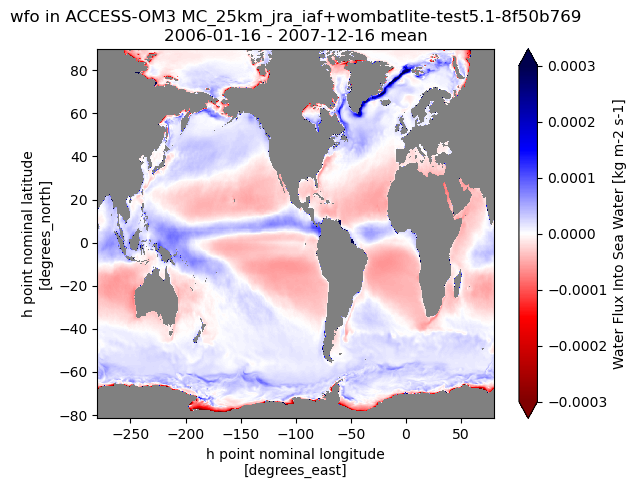

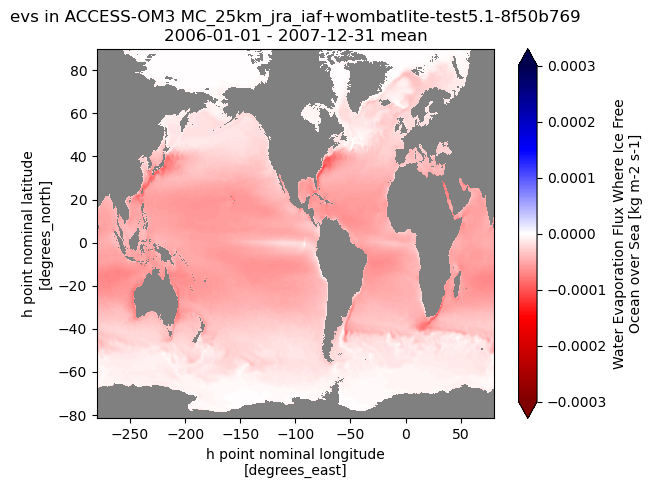

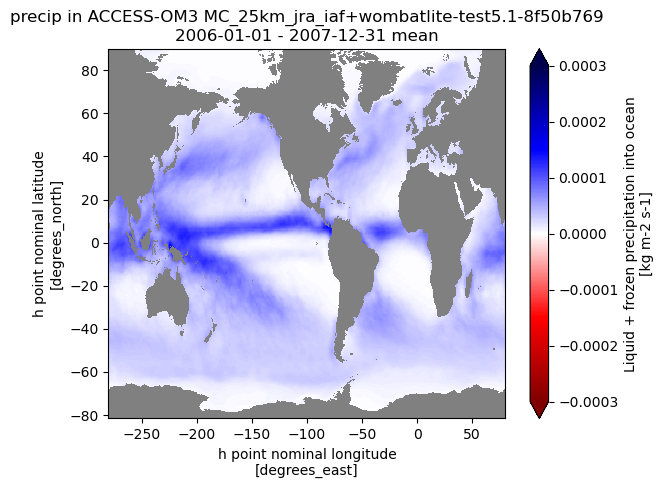

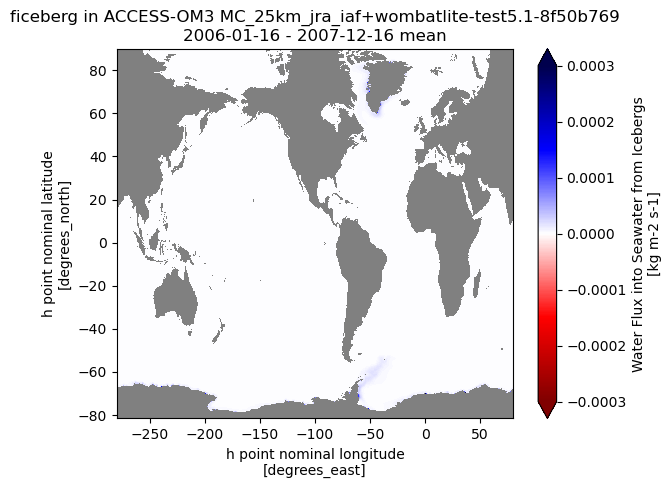

In [24]:
%%time
vmax = 3e-4
varnames = [
                "salt_flux_added_as_water",
                "wfo",
                "evs",
                "precip",
                "ficeberg",
            ]
for vname in varnames:
    print(vname)
    plt.figure()
    plt.subplot(1, 1, 1).set_facecolor('gray')  # gray land points
    data = om3vars[vname][expt].sel(time=timeslice)
    p1 = data.mean('time').load().plot(vmax=vmax,
                                       vmin=-vmax,
                                       cmap='seismic_r',
                                       add_colorbar=False)
    plt.title(f'{vname} in ACCESS-OM3 {expt}\n{data.time.values[0].strftime("%Y-%m-%d")} - {data.time.values[-1].strftime("%Y-%m-%d")} mean')
    cbar1 = plt.colorbar(p1, orientation="vertical", extend="both")
    cbar1.set_label('\n'.join(textwrap.wrap(
        f"{data.attrs['long_name']} [{data.attrs['units']}]",
        width=40)))

## Plots of SSS minus SSS monthly climatology used for restoring for OM3 and OM2

Convert OM3 sos from practical to absolute salinity, as [that's how restoring is calculated](https://github.com/ACCESS-NRI/access-om3-configs/issues/845#issuecomment-3430261033)

In [25]:
# path is a workaround - see https://forum.access-hive.org.au/t/issues-in-loading-ht-in-latest-conds-envs/6278
path = om3datastores[om3exptname].search(variable=["geolat", "geolon"], filename="access-om3.mom6.static.nc").df.loc[0, 'path']
geolon = om3datastores[om3exptname].search(variable="geolon", path=path, filename="access-om3.mom6.static.nc").to_dask().geolon
geolat = om3datastores[om3exptname].search(variable="geolat", path=path, filename="access-om3.mom6.static.nc").to_dask().geolat

# https://teos-10.github.io/GSW-Python/_modules/gsw/_wrapped_ufuncs.html#SA_from_SP
om3_sss = gsw.conversions.SA_from_SP(om3vars['sos'][om3exptname], 0, geolon, geolat)
om3_sss.attrs['long_name'] = 'Sea Surface Absolute Salinity'
om3_sss.attrs['units'] = 'g kg-1'

In [26]:
om2_sss = om2vars['surface_salt'][om2exptname]

In [27]:
# specific SSS restoring file used for each run (this is absolute salinity for OM3)
sss_restore_paths = {
    'MC_25km_era_iaf+wombatlite-test5.1-era-b3d64e3d': '/g/data/vk83/prerelease/configurations/inputs/access-om3/mom/surface_salt_restoring/global.25km/2026.09.22/salt_sfc_restore.nc',
    'MC_25km_jra_iaf+wombatlite-test5.1-8f50b769': '/g/data/vk83/prerelease/configurations/inputs/access-om3/mom/surface_salt_restoring/global.25km/2026.09.22/salt_sfc_restore.nc',
    'MC_25km_jra_iaf+wombatlite-test4-d28e0359':   '/g/data/vk83/configurations/inputs/access-om3/mom/surface_salt_restoring/global.25km/2026.06.12/salt_sfc_restore.nc',
    'MC_25km_jra_iaf+wombatlite-test3v2-00532b88': '/g/data/vk83/configurations/inputs/access-om3/mom/surface_salt_restoring/global.25km/2025.10.24/salt_sfc_restore.nc',
    'MC_25km_jra_iaf-1.0-beta-5165c0f8':           '/g/data/vk83/configurations/inputs/access-om3/mom/surface_salt_restoring/global.25km/2025.10.24/salt_sfc_restore.nc',
    'MC_100km_jra_iaf+wombatlite-test1-e1de2a94':  '/g/data/vk83/prerelease/configurations/inputs/access-om3/mom/surface_salt_restoring/global.100km/2026.09.23/salt_sfc_restore.nc',
    'MC_100km_era_iaf-test1-1d86aa55':             '/g/data/vk83/prerelease/configurations/inputs/access-om3/mom/surface_salt_restoring/global.100km/2026.09.23/salt_sfc_restore.nc',
    'MCW_100km_era_iaf-test1-961264ad':            '/g/data/vk83/prerelease/configurations/inputs/access-om3/mom/surface_salt_restoring/global.100km/2026.09.23/salt_sfc_restore.nc',
    '025deg_jra55_iaf_omip2_cycle1':               '/g/data/ik11/inputs/access-om2/input_20200530/mom_025deg/salt_sfc_restore.nc',  # https://github.com/rmholmes/025deg_jra55_iaf/blob/5235afc91185c3d6b745e90aa5174f4173e126aa/config.yaml#L41
    '025deg_jra55_ryf9091_gadi':                   '/g/data/ik11/inputs/access-om2/input_20200530/mom_025deg/salt_sfc_restore.nc',  # same md5 as input_rc/mom_025deg/salt_sfc_restore.nc in its output000/manifests/input.yaml
}

def restore_path_from_manifest(datastore):
    """Find the SSS restoring file in the payu input manifest next to the run's output."""
    import yaml
    outdir = os.path.dirname(datastore.search(variable='sos').df.path.iloc[0])
    with open(os.path.join(outdir, 'manifests', 'input.yaml')) as f:
        manifest = list(yaml.safe_load_all(f))[-1]
    return manifest['work/INPUT/salt_sfc_restore.nc']['fullpath']

if om3exptname in sss_restore_paths:
    om3_sss_restore_path = sss_restore_paths[om3exptname]
else:
    om3_sss_restore_path = restore_path_from_manifest(om3datastores[om3exptname])
print(om3_sss_restore_path)
om2_sss_restore_path = sss_restore_paths[om2exptname]

om3_sss_WOA = xr.open_dataset(om3_sss_restore_path)['asalt'].rename({'lon': 'xh', 'lat': 'yh'})  # absolute salinity

om2_sss_WOA = xr.open_dataset(om2_sss_restore_path, decode_times=False, use_cftime=False).rename({'lon': 'xt_ocean', 'lat': 'yt_ocean'})
# nasty kludges to fix up time axis
om2_sss_WOA['time'] = om2_sss_WOA['time']*30  # roughly convert months to days
om2_sss_WOA['time'].attrs.pop('calendar_type', None)
om2_sss_WOA['time'].attrs['calendar'] = 'gregorian'
om2_sss_WOA['time'].attrs['units'] = 'days since 1900-01-01 00:00:00'  # to suit gregorian
om2_sss_WOA = xr.decode_cf(om2_sss_WOA)['salt']
# fix grid mismatch in tripolar region
om2_sss_WOA['xt_ocean'] = om2_sss['xt_ocean']
om2_sss_WOA['yt_ocean'] = om2_sss['yt_ocean']

/g/data/vk83/prerelease/configurations/inputs/access-om3/mom/surface_salt_restoring/global.25km/2026.09.22/salt_sfc_restore.nc


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14d45d63c6e0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:50: UserWarning: An error occurred while loading the ArgoVis data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14d45f148560>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:66: UserWarning: An error occurred while loading the GDAC data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14d45dda6240>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:91: UserWarning: An error occurred while loading the ERDDAP index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14d45dda5b50>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:107: UserWarning: An error occurred while loading the GDAC index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14d46011fe30>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'argo' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14d45f9754f0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14d45ed0a0c0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


In [28]:
%%time
om3_sss_bias = (
        om3_sss.sel(time=timeslice).groupby('time.month').mean('time')
        - om3_sss_WOA.groupby('time.month').mean('time')
    ).load()

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 152.43 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


CPU times: user 4.34 s, sys: 1.66 s, total: 6 s
Wall time: 7.89 s


In [29]:
%%time
om2_sss_bias = (
        om2_sss.sel(time=om2timeslice).groupby('time.month').mean('time')
        - om2_sss_WOA.groupby('time.month').mean('time')
    ).load()

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 72.70 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


CPU times: user 3.58 s, sys: 1.2 s, total: 4.78 s
Wall time: 5.26 s


Saved /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/mkmd/SSS_Restoring_Timeseries_01.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/mkmd/SSS_Restoring_Timeseries.md


Lines appended to /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/mkmd/SSS_Restoring_Timeseries.md successfully.


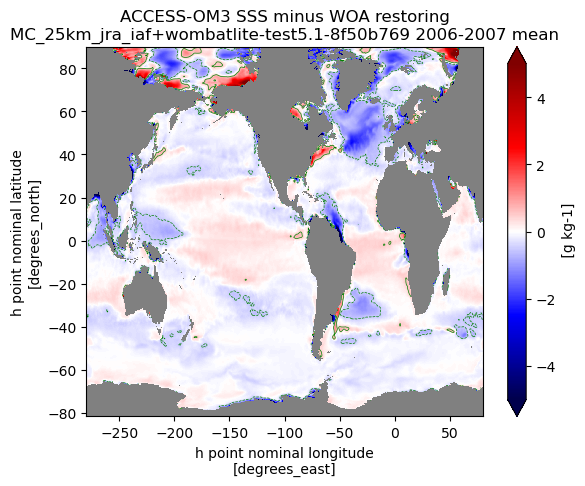

In [30]:
vmax = 5
MAX_DELTA_SRESTORE = 0.5  # psu

plt.figure()
plt.subplot(1, 1, 1).set_facecolor('gray')  # gray land points
om3_sss_bias.mean('month').plot(vmax=vmax, vmin=-vmax, cmap='seismic')
om3_sss_bias.mean('month').plot.contour(levels = [-MAX_DELTA_SRESTORE, MAX_DELTA_SRESTORE], colors='g', linewidths=0.5)
plt.title(f"")
plt.title(f'ACCESS-OM3 SSS minus WOA restoring\n{om3exptname} {period}')
mkmd.savefig(plt.gcf(), "SSS Restoring", "ACCESS-OM3 sea surface salinity bias relative to WOA restoring target. [GitHub issue: SSS restoring maps/timeseries](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/44)")

Saved /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/mkmd/SSS_Restoring_Timeseries_02.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/mkmd/SSS_Restoring_Timeseries.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/mkmd/SSS_Restoring_Timeseries.md successfully.


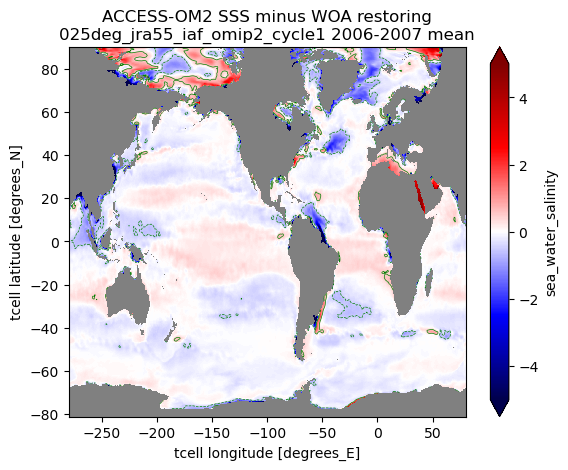

In [31]:
plt.figure()
plt.subplot(1, 1, 1).set_facecolor('gray')  # gray land points
om2_sss_bias.mean('month').plot(vmax=vmax, vmin=-vmax, cmap='seismic')
om2_sss_bias.mean('month').plot.contour(levels = [-MAX_DELTA_SRESTORE, MAX_DELTA_SRESTORE], colors='g', linewidths=0.5)
plt.title(f'ACCESS-OM2 SSS minus WOA restoring\n{om2exptname} {om2period}')
mkmd.savefig(plt.gcf(), "SSS Restoring", "ACCESS-OM2 sea surface salinity bias relative to WOA restoring target. [GitHub issue: SSS restoring maps/timeseries](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/44)")

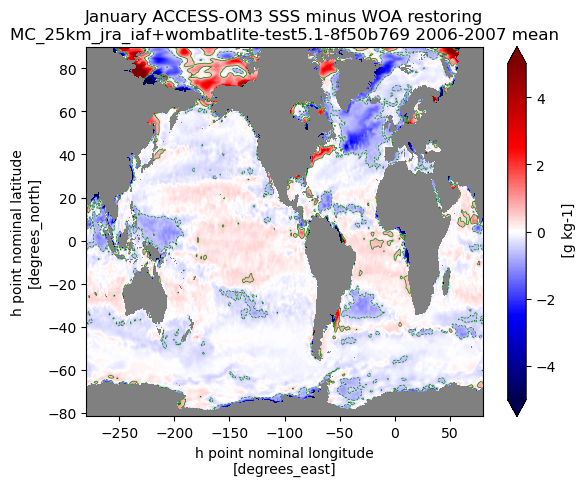

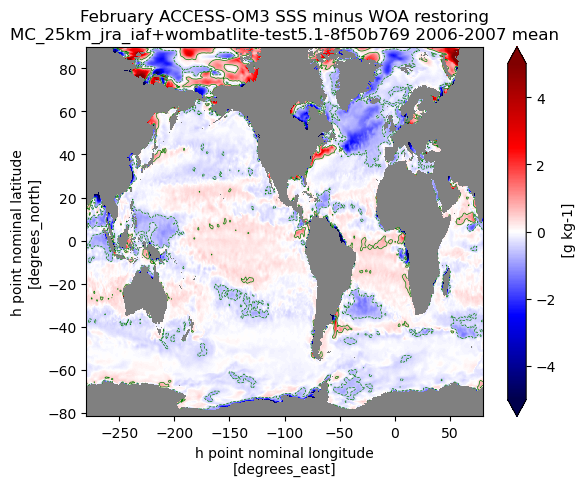

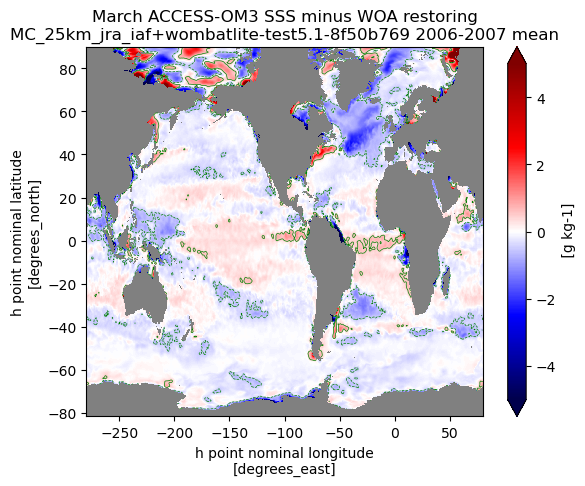

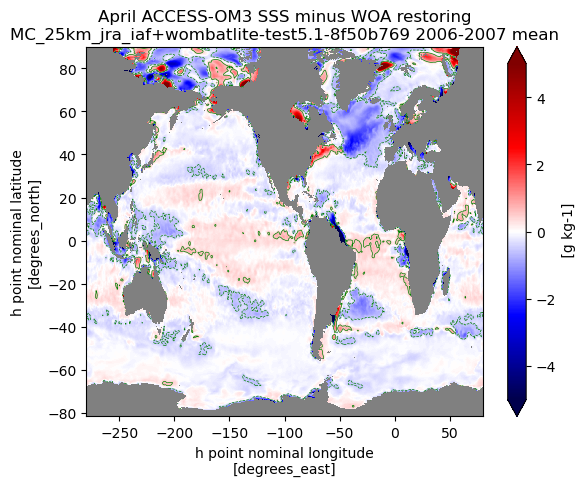

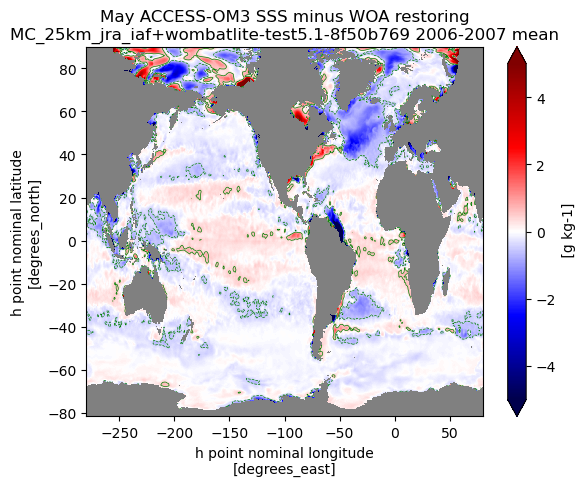

...

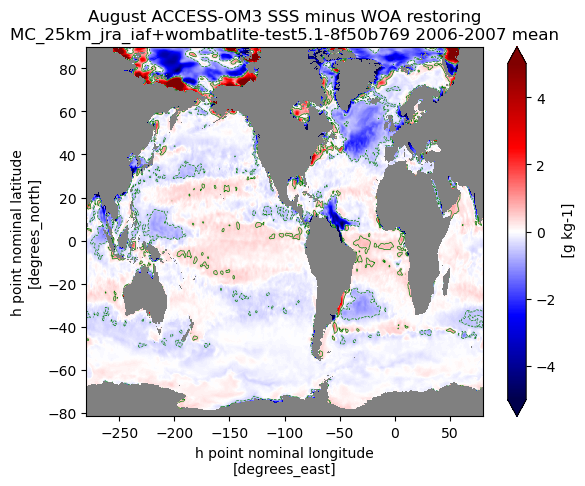

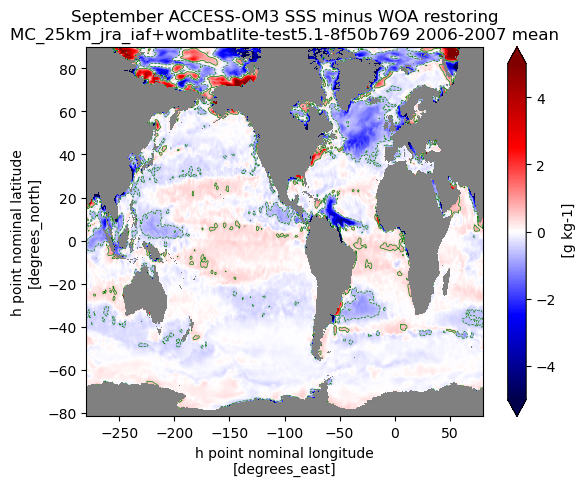

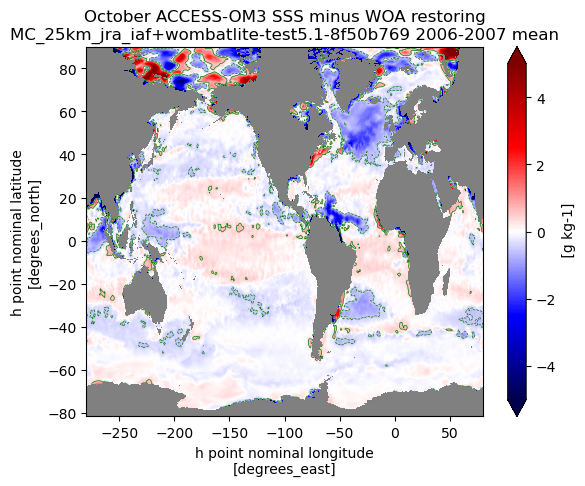

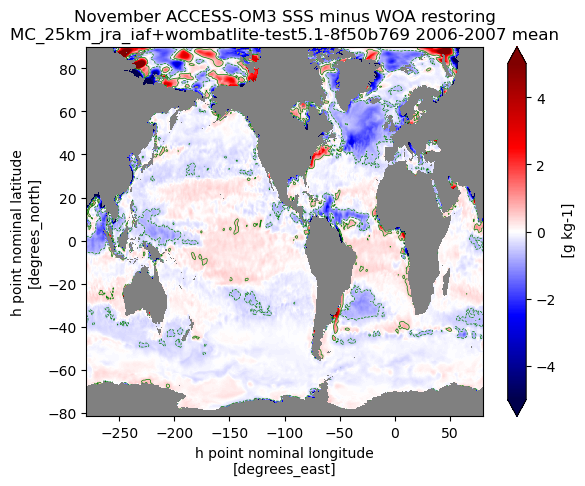

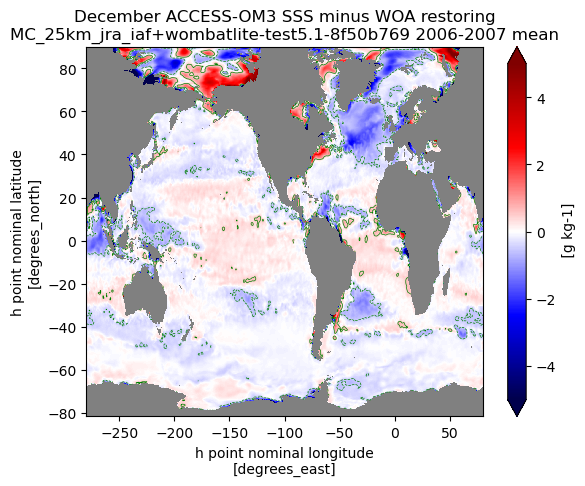

In [32]:
for m in range(12):
    plt.figure()
    plt.subplot(1, 1, 1).set_facecolor('gray')  # gray land points
    om3_sss_bias.sel(month=m+1).plot(vmax=vmax, vmin=-vmax, cmap='seismic')
    om3_sss_bias.sel(month=m+1).plot.contour(levels = [-MAX_DELTA_SRESTORE, MAX_DELTA_SRESTORE], colors='g', linewidths=0.5)
    plt.title(f'{calendar.month_name[m+1]} ACCESS-OM3 SSS minus WOA restoring\n{om3exptname} {period}')

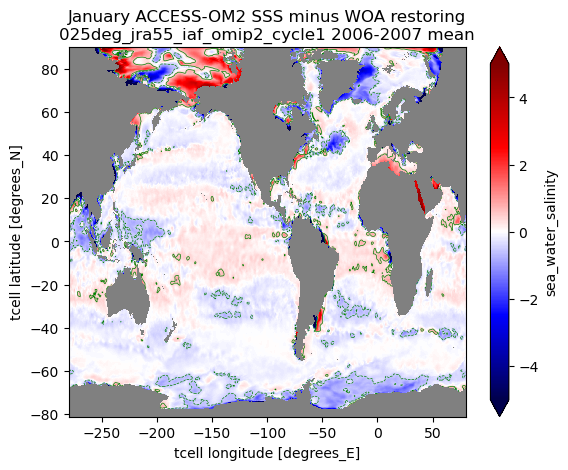

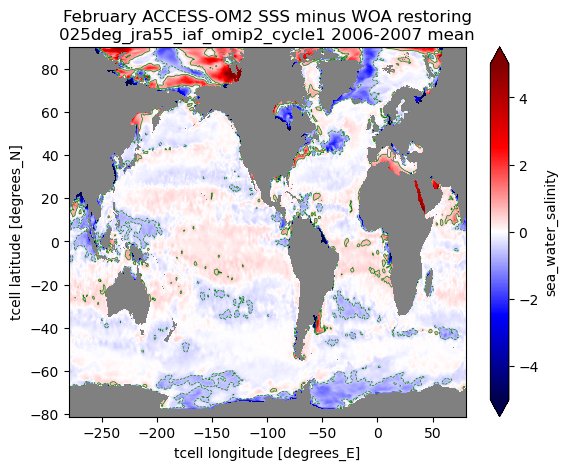

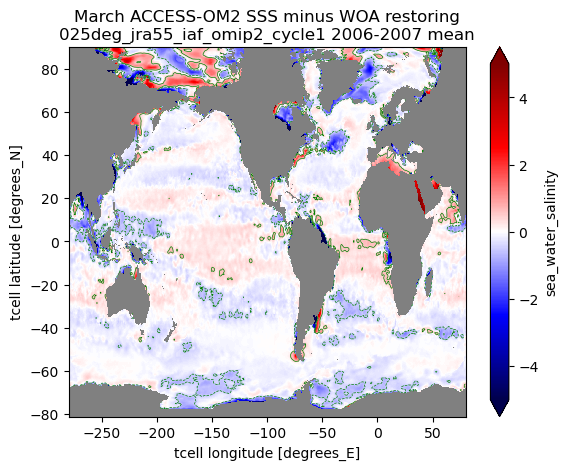

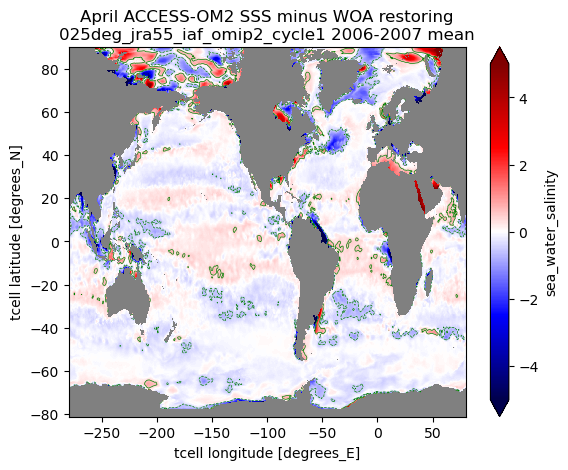

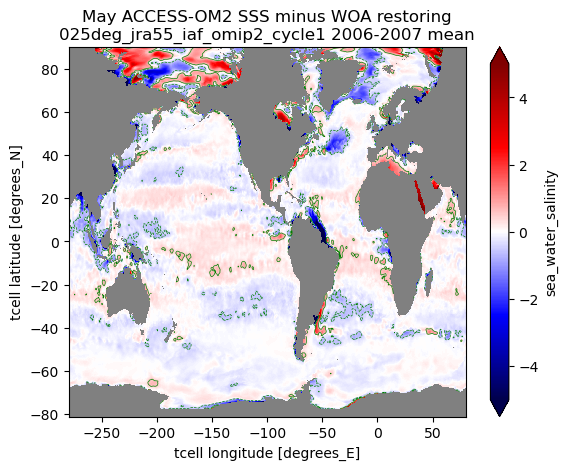

...

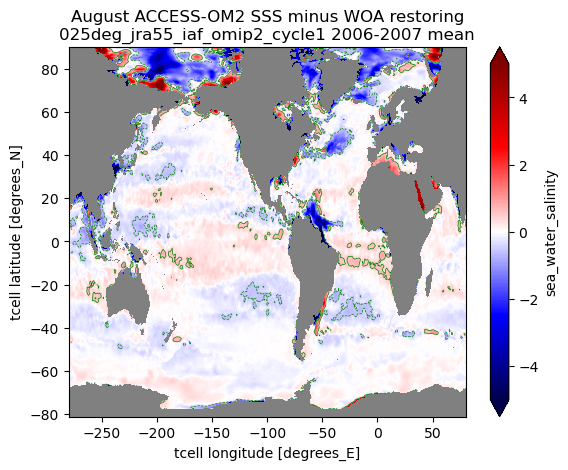

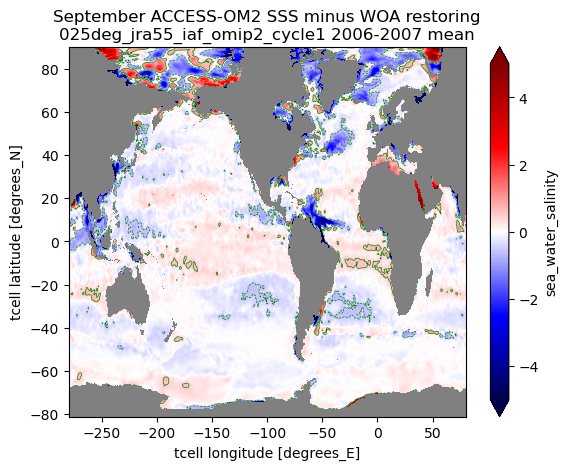

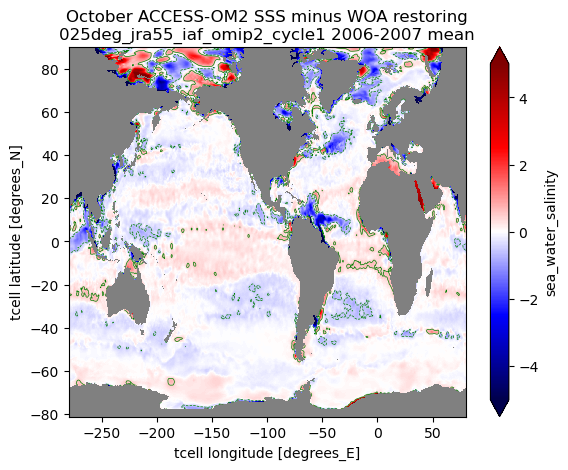

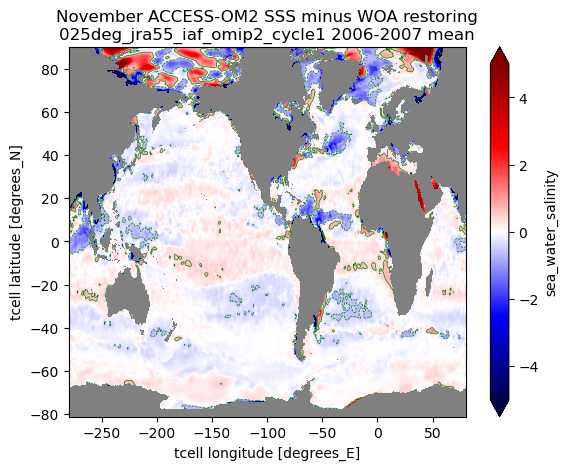

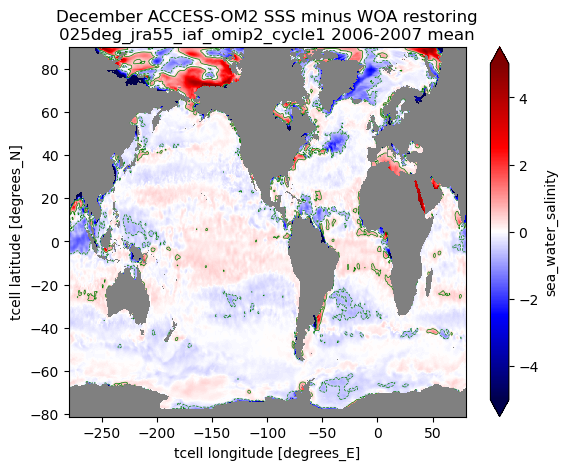

In [33]:
for m in range(12):
    plt.figure()
    plt.subplot(1, 1, 1).set_facecolor('gray')  # gray land points
    om2_sss_bias.sel(month=m+1).plot(vmax=vmax, vmin=-vmax, cmap='seismic')
    om2_sss_bias.sel(month=m+1).plot.contour(levels = [-MAX_DELTA_SRESTORE, MAX_DELTA_SRESTORE], colors='g', linewidths=0.5)
    plt.title(f'{calendar.month_name[m+1]} ACCESS-OM2 SSS minus WOA restoring\n{om2exptname} {om2period}')